# Sensibilidad directa e identificabilidad

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` es requerido por el operador directo MT.

## Datos

Registro medido solo QC y artefacto sintético de calibración separado; no mezcle estas clases de evidencia.

## Método

El operador estratificado del repositorio usa respuesta de semiespacio `Z=√(iωμ₀ρ)` y la propaga recursivamente por capas finitas usando `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)` y `t=tanh(kh)`. La base es infinita; la geometría es 1D, isótropa y cuasiestática. Use las funciones existentes `electromagnetics.impedance` y `curves`, sin reimplementarlas. Compare la verdad sintética exacta con un ajuste guardado sobre las frecuencias versionadas, graficando resistividad aparente (Ω·m) y fase (grados) frente al período (s). Curvas parecidas no prueban unicidad de resistividad o espesor: dimensionalidad, static shift, errores correlacionados y espesor fijo quedan fuera de la calibración.

Los parámetros son log-resistividades: positivos por construcción y pasos iguales son cambios multiplicativos iguales. Residuos complejos usan sigma por componente real; ambas partes aportan al ajuste. Frecuencias no son muestras independientes de profundidad: kernels se solapan y un período no identifica una interfaz. Sensibilidad local y cobertura dependen de parametrización fija y no descartan equivalencia global.

## Estado del arte

El estado del arte no es una tabla de posiciones: separe formulación publicada, implementación del producto y evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib', 'scipy']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Call the repository layered-earth forward operator on its synthetic calibration target.
import json,sys
from pathlib import Path
sys.path.insert(0,str(root/"data-pipeline")); import electromagnetics as em
from electromagnetics import impedance,curves
cal=json.loads((root/"data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8")); f=cal["frequencies_hz"]; rho=cal["calibration_model"]; h=cal["fixed_thickness_m"]; z=impedance(rho,h,f); truth=curves(z,f)
print("synthetic rho Ω·m",rho,"fixed thickness m",h,"n frequencies",len(f))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
synthetic rho Ω·m [180.0, 20.0] fixed thickness m [450.0] n frequencies 24


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

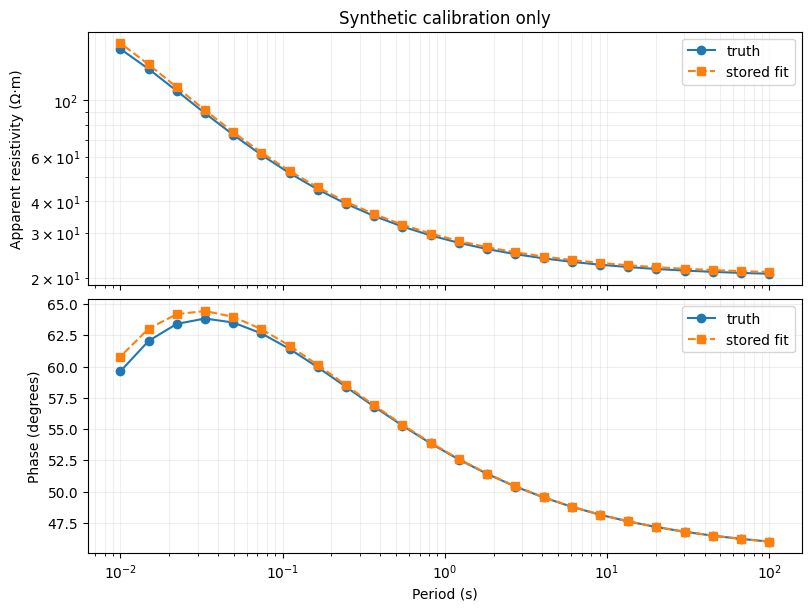

stored fitted rho Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Forward-project a stored fitted model and compare physical response curves.
import matplotlib.pyplot as plt
fit=cal["rows"][0]["model"]; other=curves(impedance(fit,h,f),f); T=1/np.asarray(f)
fig,ax=plt.subplots(2,1,figsize=(8,6),sharex=True,constrained_layout=True); ax[0].loglog(T,truth["apparent"],"o-",label="truth"); ax[0].loglog(T,other["apparent"],"s--",label="stored fit"); ax[1].semilogx(T,truth["phase"],"o-",label="truth"); ax[1].semilogx(T,other["phase"],"s--",label="stored fit")
ax[0].set_ylabel("Apparent resistivity (Ω·m)"); ax[1].set_ylabel("Phase (degrees)"); ax[1].set_xlabel("Period (s)"); [a.grid(True,which="both",alpha=.2) or a.legend() for a in ax]; ax[0].set_title("Synthetic calibration only"); plt.show(); print("stored fitted rho Ω·m",fit)

### Experimento sintético: cobertura de frecuencias, ruido y equivalencia de espesor

Este experimento directo adicional **sintético** se separa del registro medido `cl061`. El operador estratificado del repositorio genera una respuesta exacta de tres capas. Su rutina implementada `identifiability` linealiza respecto de log-resistividad con ambos espesores fijos. Compare la banda completa con subconjuntos solo de bajas y altas frecuencias usando el mismo modelo y la misma incertidumbre por componente. Los valores singulares y la SD local de log-resistividad son diagnósticos condicionales de sensibilidad, no incertidumbre posterior ni prueba de unicidad.

Una segunda perturbación directa aumenta conjuntamente el espesor y la resistividad de la capa conductora finita, preservando aproximadamente su conductancia (`h/ρ`). Compare el cambio de respuesta compleja con la escala de ruido declarada. Esta equivalencia conocida es aproximada para una respuesta estratificada de frecuencia finita. Muestra el supuesto de espesor fijo; no es una segunda inversión, una afirmación de geología recuperada ni evidencia sobre `cl061`.

In [3]:
# Experimento solo sintético: sensibilidad local con espesor fijo y ventanas de frecuencia.
f_syn=np.logspace(-3,2,60); h_syn=np.array([300.,700.]); rho_syn=np.array([80.,12.,250.])
z_syn=impedance(rho_syn,h_syn,f_syn)
sigma_syn=np.maximum(.03*np.abs(z_syn),1e-12) # SD de cada componente real e imaginaria independiente
bands={"banda completa 0.001–100 Hz":np.ones(len(f_syn),dtype=bool),
       "baja frecuencia ≤0.1 Hz":f_syn<=.1,
       "alta frecuencia ≥1 Hz":f_syn>=1.}
diags={}
for label,mask in bands.items():
 d=em.identifiability(rho_syn,h_syn,f_syn,sigma_syn,mask)
 diags[label]=d
 print(label,"N=",int(mask.sum()),"rango efectivo=",d["effective_rank"],"/",d["parameter_count"],
       "valores singulares=",np.round(d["singular_values"],3),"SD local log-rho=",np.round(d["local_logrho_sd"],3),
       "capas no resueltas=",d["unresolved_layers"],"estado=",d["status"])
# Perturbación directa h/rho de la capa conductora finita.
rho_trade=np.array([rho_syn[0],rho_syn[1]*1.15,rho_syn[2]])
h_trade=np.array([h_syn[0],h_syn[1]*1.15])
z_trade=impedance(rho_trade,h_trade,f_syn)
whitened=np.abs(z_trade-z_syn)/sigma_syn
trade_wrms=float(np.sqrt(np.mean(whitened**2)/2))
print("Equivalencia sintética de conductancia; h base m=",h_syn,"rho ohm m=",rho_syn)
print("h perturbado m=",h_trade,"rho ohm m=",rho_trade,"; WRMS por componente blanqueado=",trade_wrms)

banda completa 0.001–100 Hz N= 60 rango efectivo= 3 / 3 valores singulares= [107.981  61.827  27.976] SD local log-rho= [0.036 0.011 0.015] capas no resueltas= [] estado= locally_resolved
baja frecuencia ≤0.1 Hz N= 24 rango efectivo= 2 / 3 valores singulares= [71.098 31.793  0.1  ] SD local log-rho= [9.974 0.668 0.022] capas no resueltas= [0] estado= unresolved
alta frecuencia ≥1 Hz N= 24 rango efectivo= 3 / 3 valores singulares= [64.944 27.966  6.79 ] SD local log-rho= [0.036 0.017 0.147] capas no resueltas= [] estado= locally_resolved
Equivalencia sintética de conductancia; h base m= [300. 700.] rho ohm m= [ 80.  12. 250.]
h perturbado m= [300. 805.] rho ohm m= [ 80.   13.8 250. ] ; WRMS por componente blanqueado= 0.5429574698818997


### Graficar sensibilidad y compromiso

Esta celda representa los rangos de sensibilidad y el compromiso paramétrico calculados arriba; no ajusta ni evalúa datos de campo.


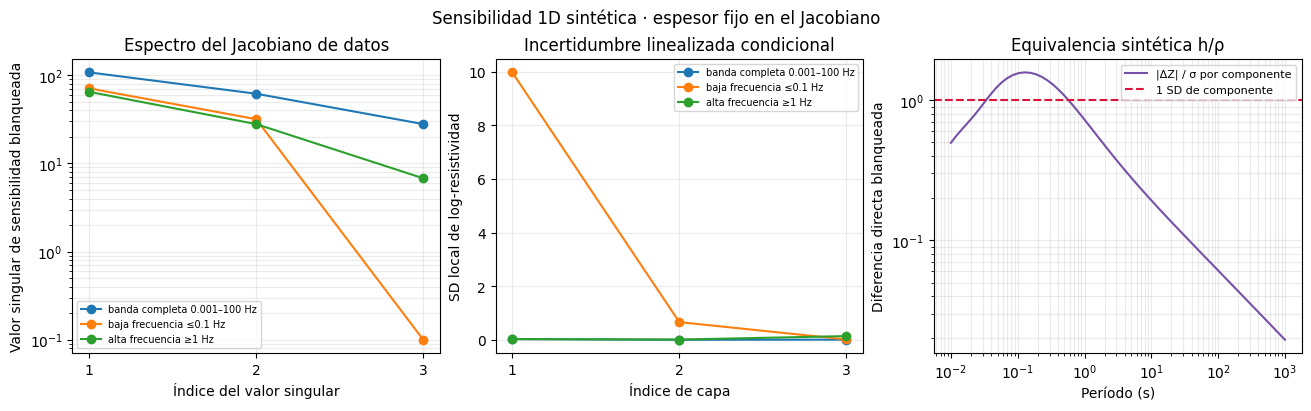

In [4]:
# Execute the documented experiment with the repository evidence.
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for label,d in diags.items():
 s=np.asarray(d["singular_values"],float)
 ax[0].semilogy(np.arange(1,len(s)+1),s,marker="o",label=label)
 ax[1].plot(np.arange(1,len(rho_syn)+1),d["local_logrho_sd"],marker="o",label=label)
ax[0].set_xlabel("Índice del valor singular"); ax[0].set_ylabel("Valor singular de sensibilidad blanqueada")
ax[0].set_title("Espectro del Jacobiano de datos"); ax[1].set_xlabel("Índice de capa"); ax[1].set_ylabel("SD local de log-resistividad")
ax[1].set_title("Incertidumbre linealizada condicional")
for a in ax[:2]: a.set_xticks(np.arange(1,4)); a.grid(True,which="both",alpha=.25); a.legend(fontsize=7)
T=1/f_syn; ax[2].loglog(T,whitened,label="|ΔZ| / σ por componente",color="#7651a8")
ax[2].axhline(1,color="crimson",ls="--",label="1 SD de componente")
ax[2].set_xlabel("Período (s)"); ax[2].set_ylabel("Diferencia directa blanqueada"); ax[2].set_title("Equivalencia sintética h/ρ")
ax[2].grid(True,which="both",alpha=.25); ax[2].legend(fontsize=8)
fig.suptitle("Sensibilidad 1D sintética · espesor fijo en el Jacobiano"); plt.show()

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)